# Bank Marketing Subscription Prediction

## Project Overview
This project uses machine learning to predict whether a bank customer will subscribe to a term deposit.

## Problem Statement
The goal is to identify potential subscribers and compare different classification models.

## Data Source
Kaggle: adityamhaske/bank-marketing-dataset

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [50]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

## 1. Data Loading and Initial Inspection

In this section, we load the Bank Marketing dataset and inspect its structure, features, data types, and target variable.

In [ ]:
import kagglehub


path = kagglehub.dataset_download("adityamhaske/bank-marketing-dataset")

print("Path to dataset files:", path)

100%|██████████| 576k/576k [00:00<00:00, 57.7MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/adityamhaske/bank-marketing-dataset/versions/3


In [ ]:
import os

In [ ]:
print(os.listdir(path))

['bank.csv', 'bank-full.csv']


In [ ]:
file_path = os.path.join(path,'bank-full.csv')

df = pd.read_csv(file_path,sep =';')
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no


In [ ]:
df.shape

(45211, 17)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [ ]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [ ]:
df['y'].value_counts()

,count
y,
no,39922
yes,5289


In [ ]:
df.nunique()

,0
age,77
job,12
marital,3
education,4
default,2
balance,7168
housing,2
loan,2
contact,3
day,31


In [ ]:
df.duplicated().sum()

np.int64(0)

## 2. Exploratory Data Analysis (EDA)

In this section, we analyze numerical and categorical features using descriptive statistics and visualizations. We also examine feature distributions, outliers, class imbalance, and relationships between features and the target variable.

In [ ]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


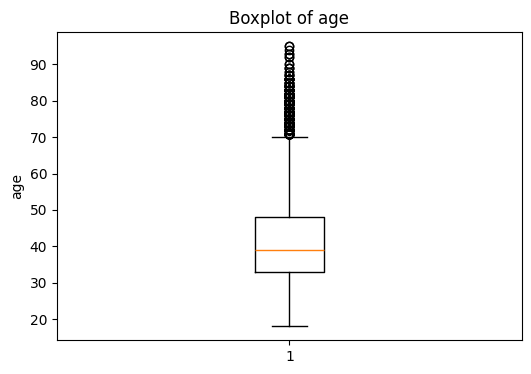

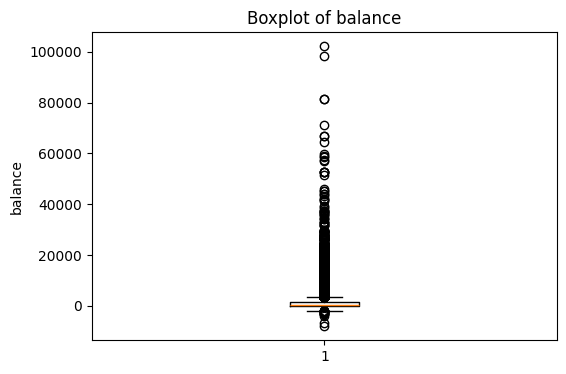

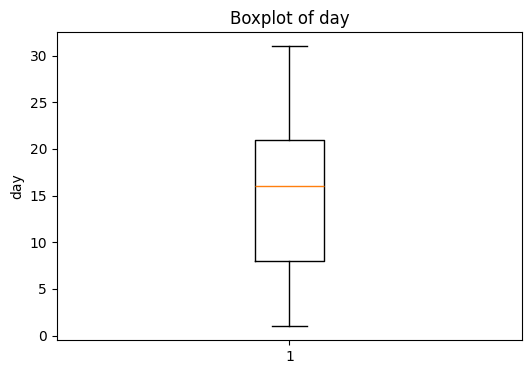

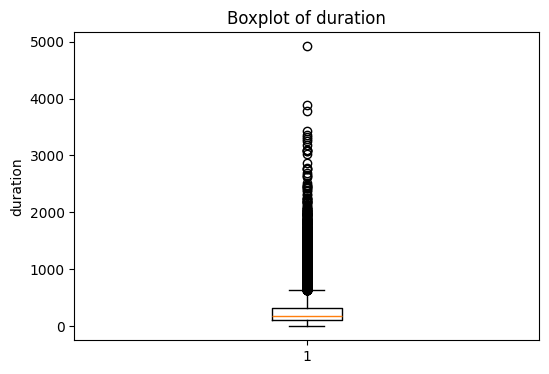

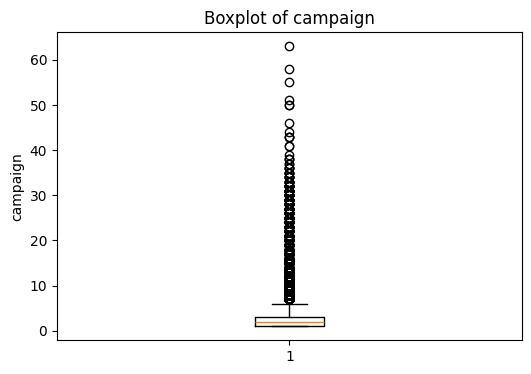

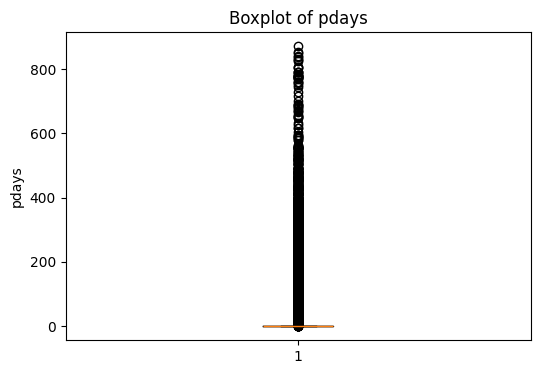

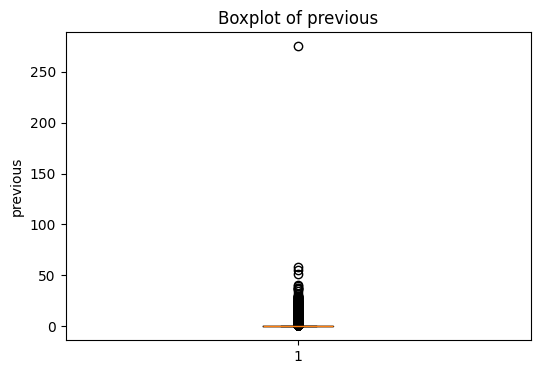

In [ ]:
nemurical_cols = df.select_dtypes(include = "number").columns

for col in nemurical_cols :
  plt.figure(figsize=(6,4))
  plt.boxplot(df[col])
  plt.title(f'Boxplot of {col}')
  plt.ylabel(col)
  plt.show()


In [ ]:
for col in df.select_dtypes(include='object').columns:
    print(f"\n{col}")
    print(df[col].value_counts())


job
job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64

marital
marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64

education
education
secondary    23202
tertiary     13301
primary       6851
unknown       1857
Name: count, dtype: int64

default
default
no     44396
yes      815
Name: count, dtype: int64

housing
housing
yes    25130
no     20081
Name: count, dtype: int64

loan
loan
no     37967
yes     7244
Name: count, dtype: int64

contact
contact
cellular     29285
unknown      13020
telephone     2906
Name: count, dtype: int64

month
month
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
apr     2932
feb     2649
jan     1403
oct      738
sep      579
mar      477
dec      214
Name: count

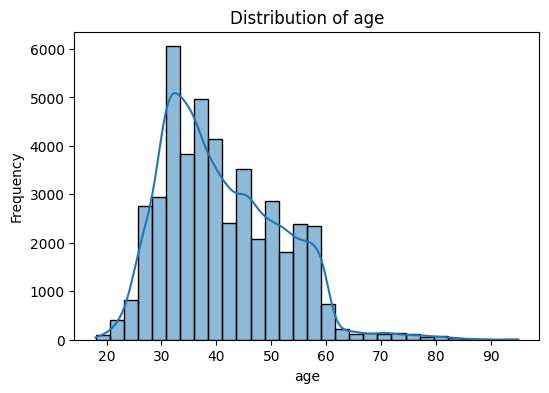

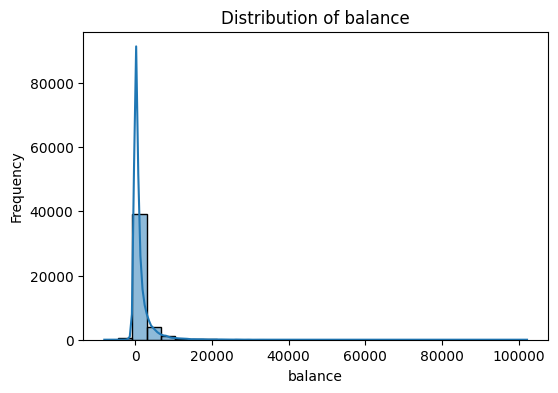

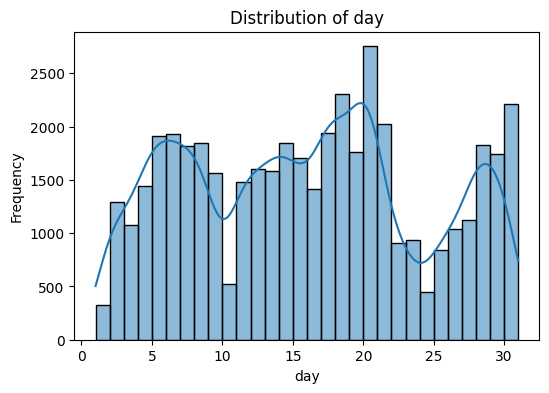

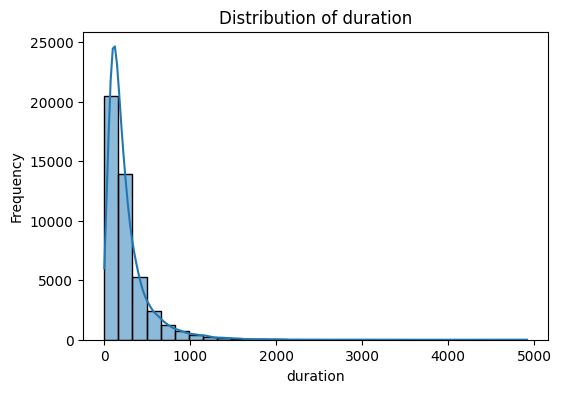

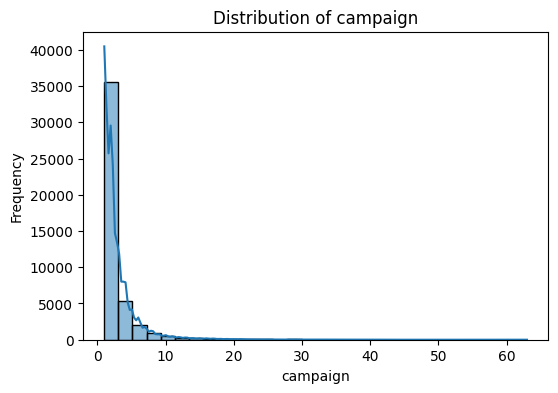

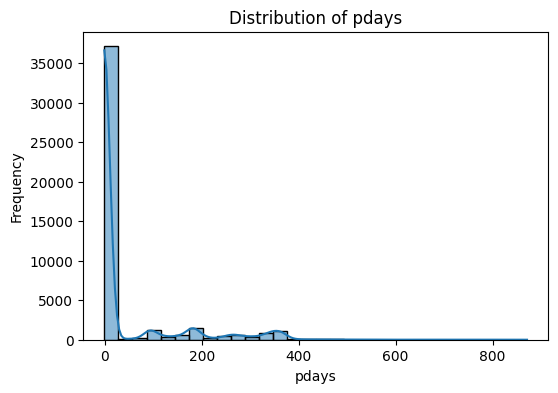

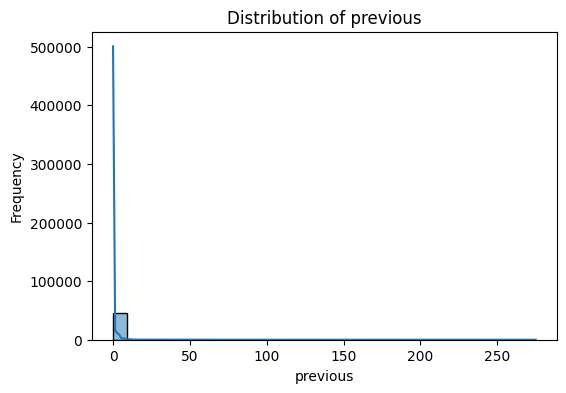

In [ ]:

numeric_cols = df.select_dtypes(include='number').columns

for col in numeric_cols:
    plt.figure(figsize=(6, 4))
    sns.histplot(df[col], bins=30, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

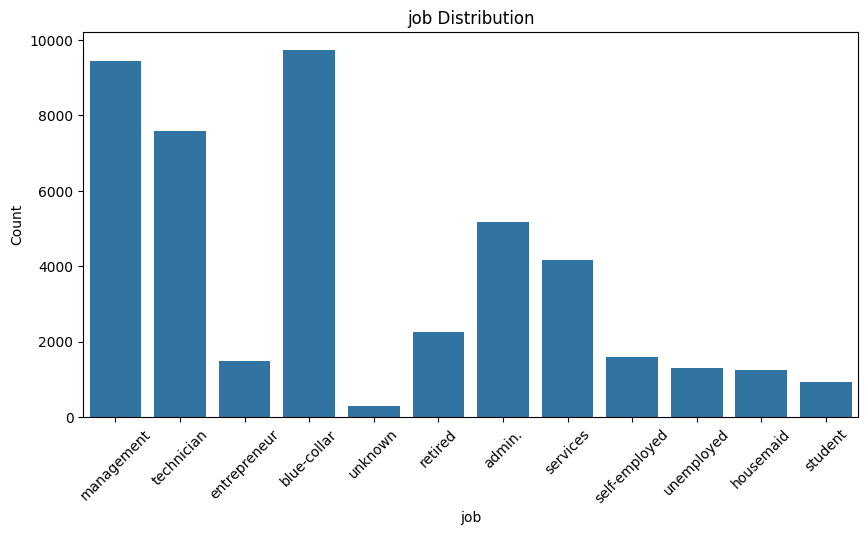

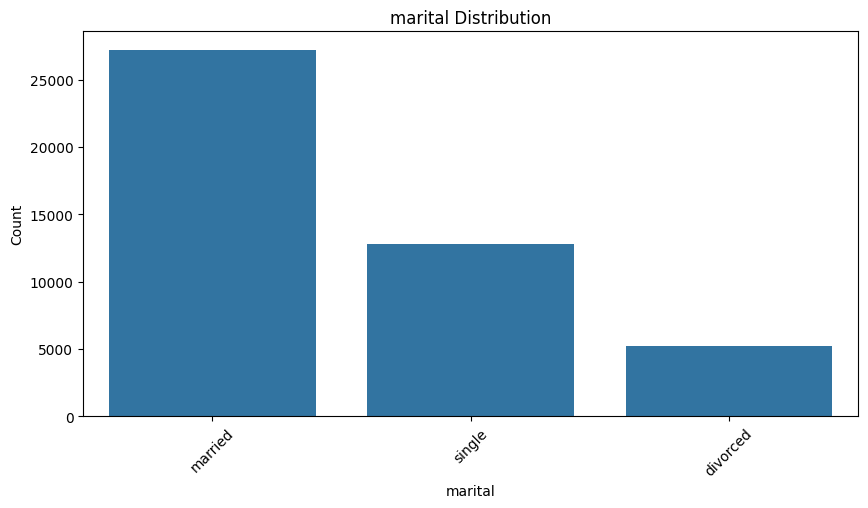

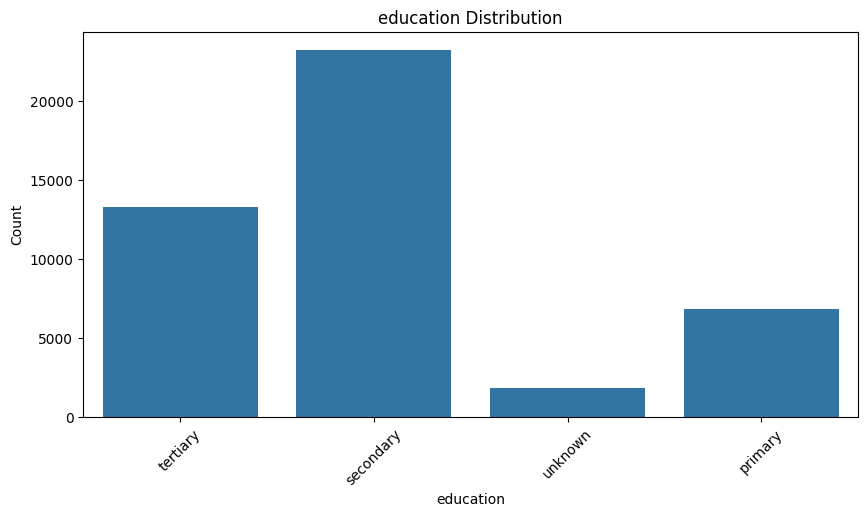

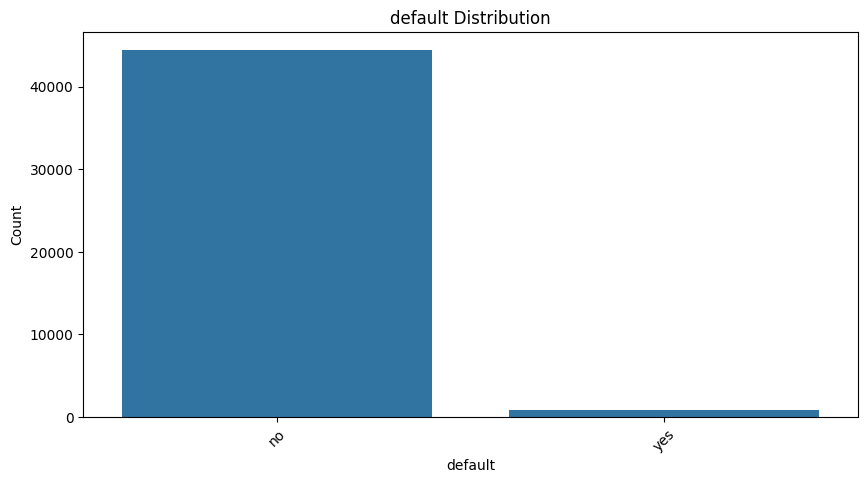

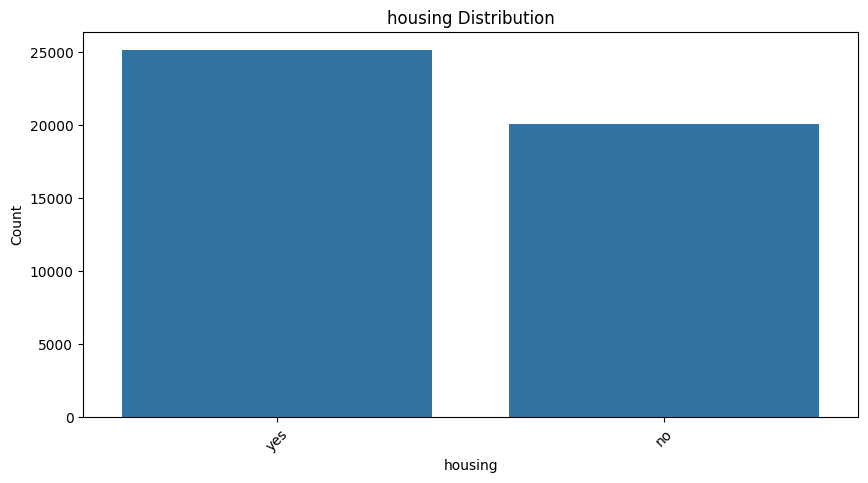

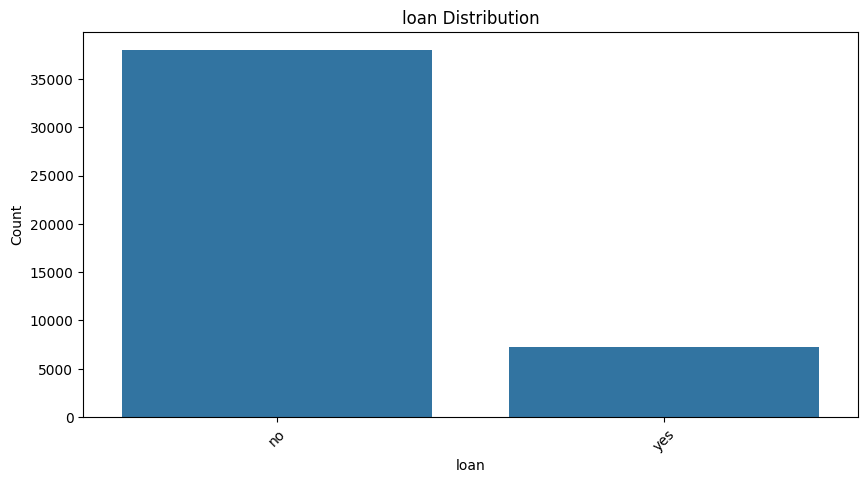

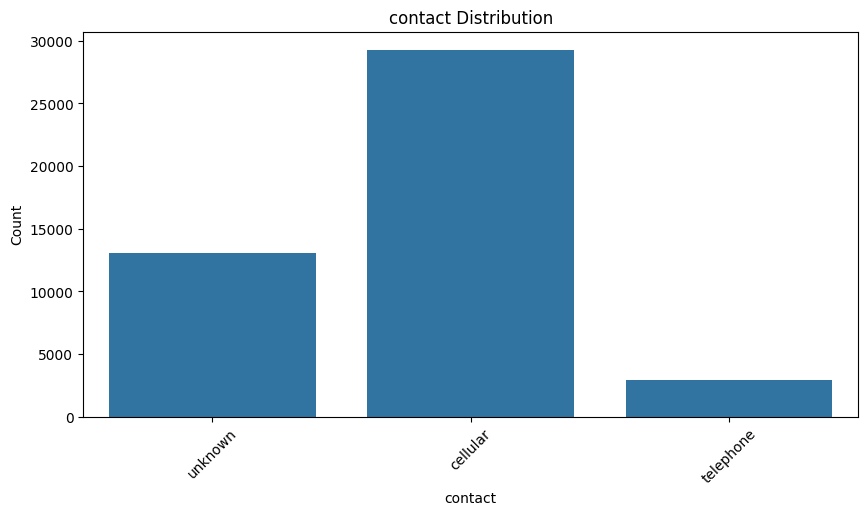

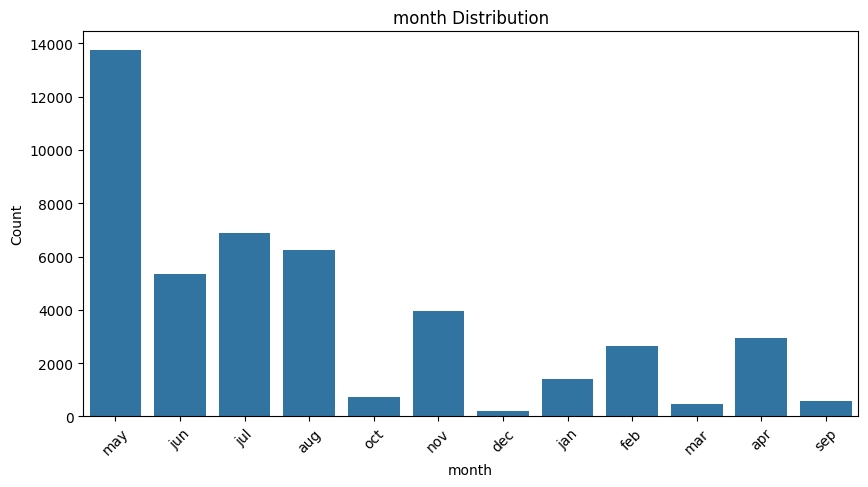

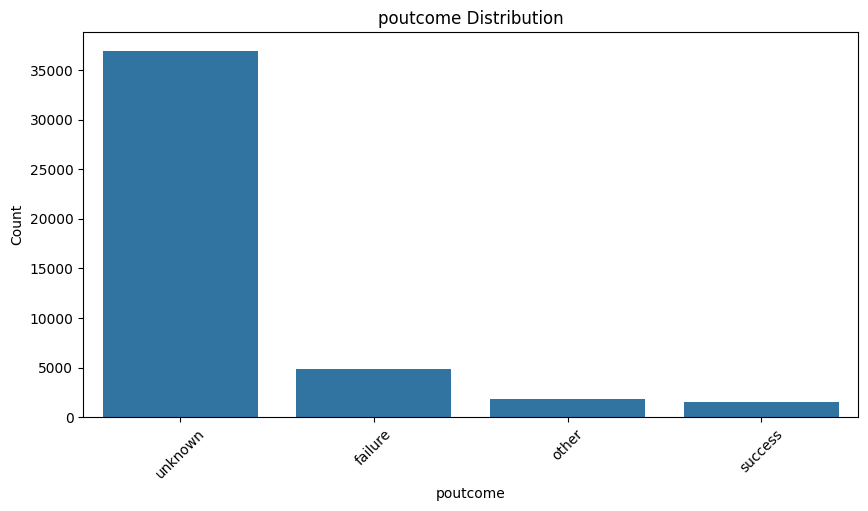

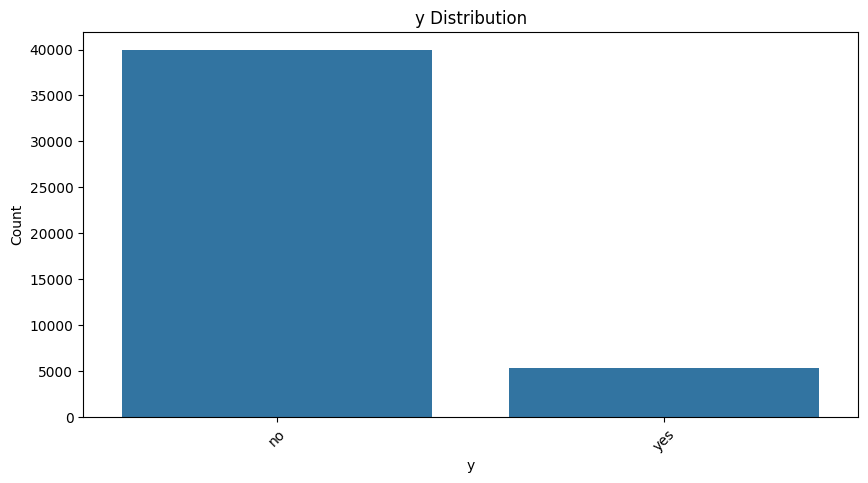

In [ ]:

categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df, x=col)

    plt.title(f'{col} Distribution')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.show()

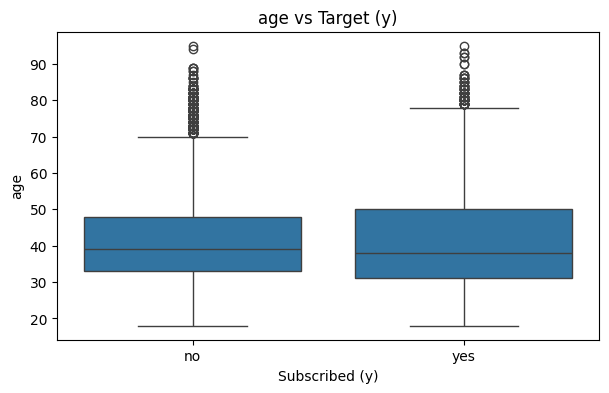

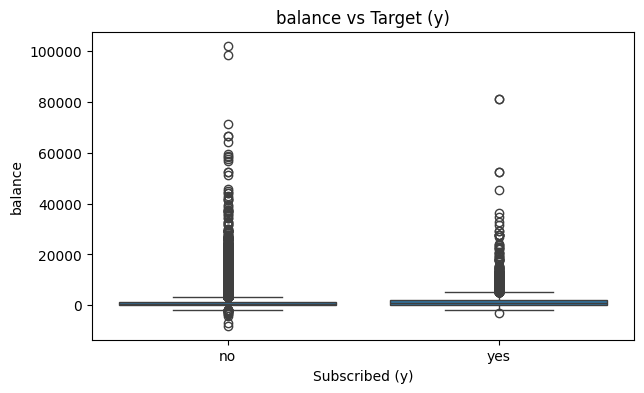

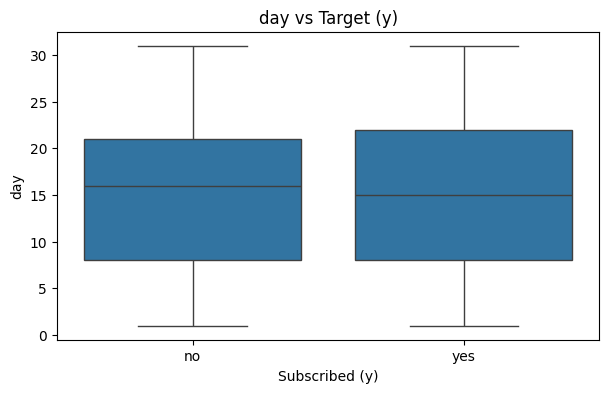

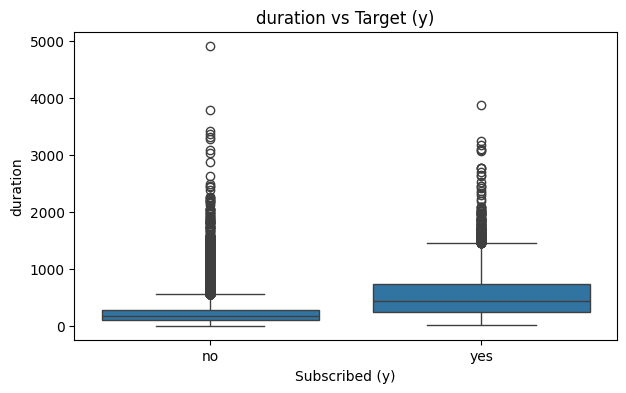

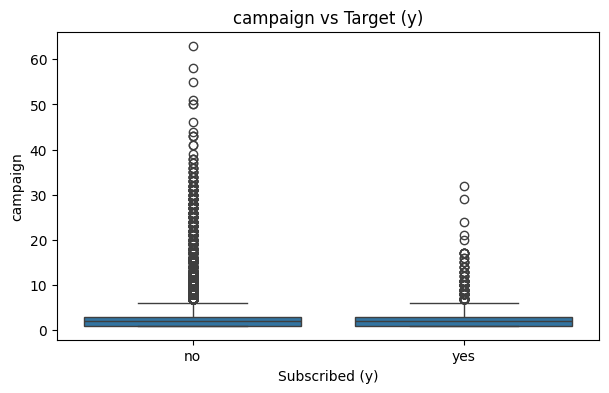

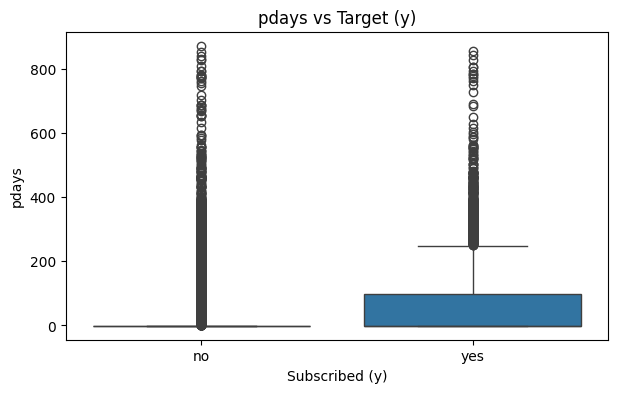

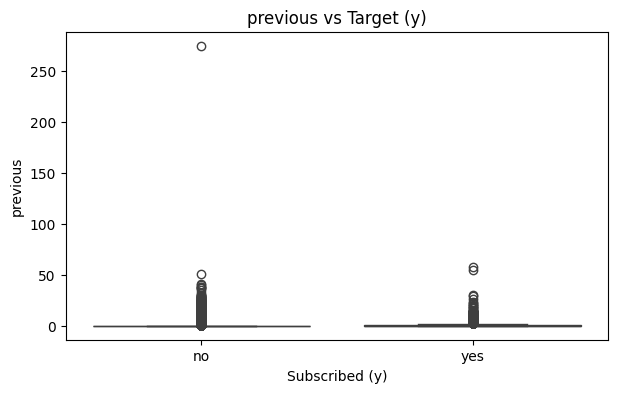

In [ ]:
for col in nemurical_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x='y', y=col)

    plt.title(f'{col} vs Target (y)')
    plt.xlabel('Subscribed (y)')
    plt.ylabel(col)
    plt.show()

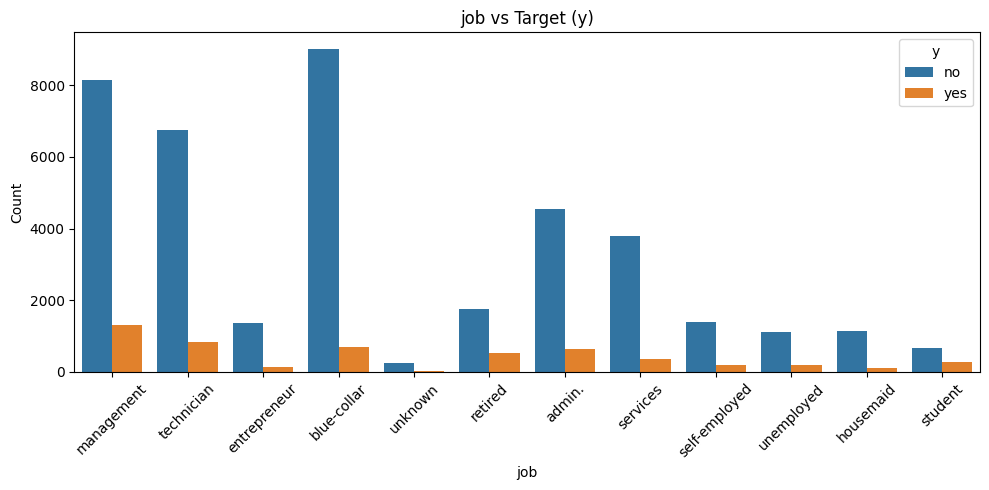

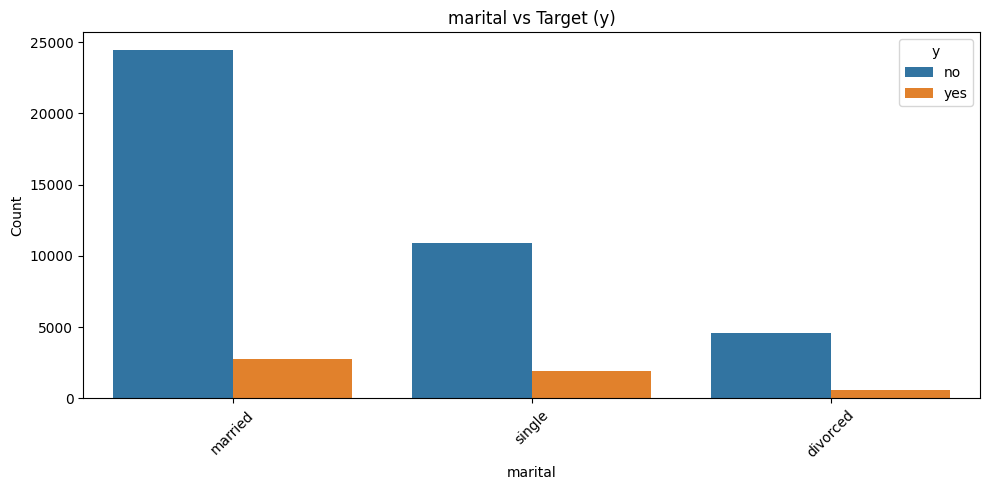

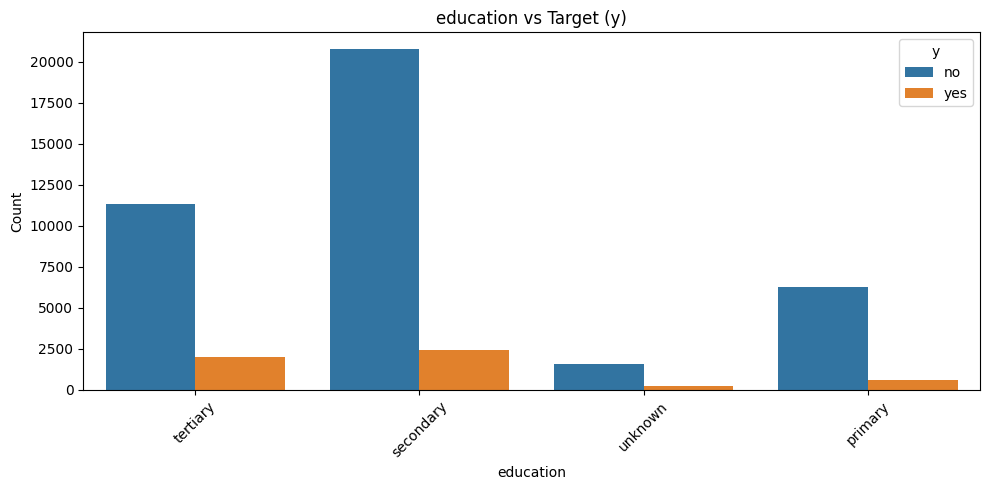

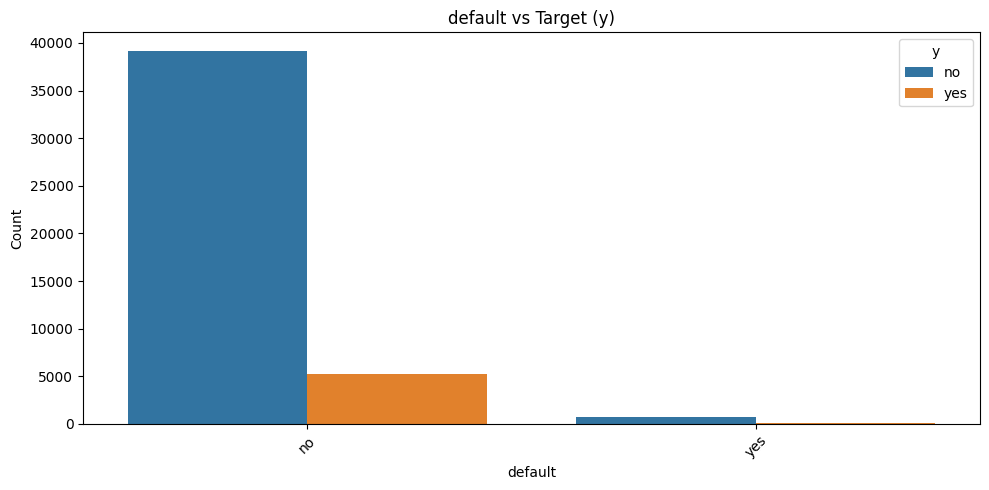

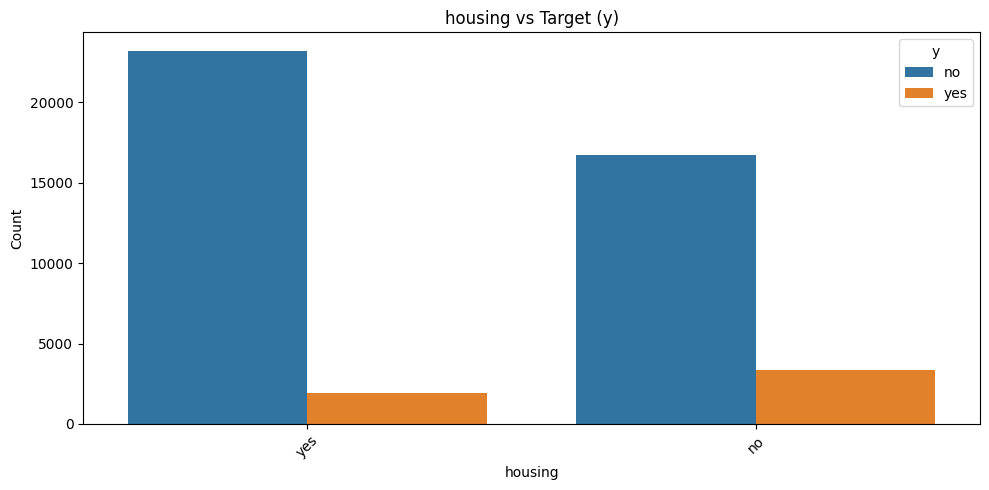

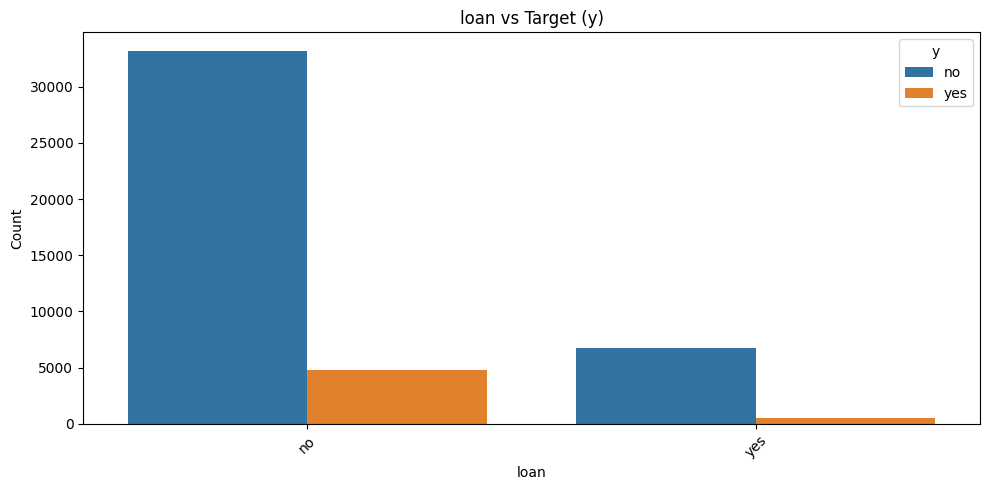

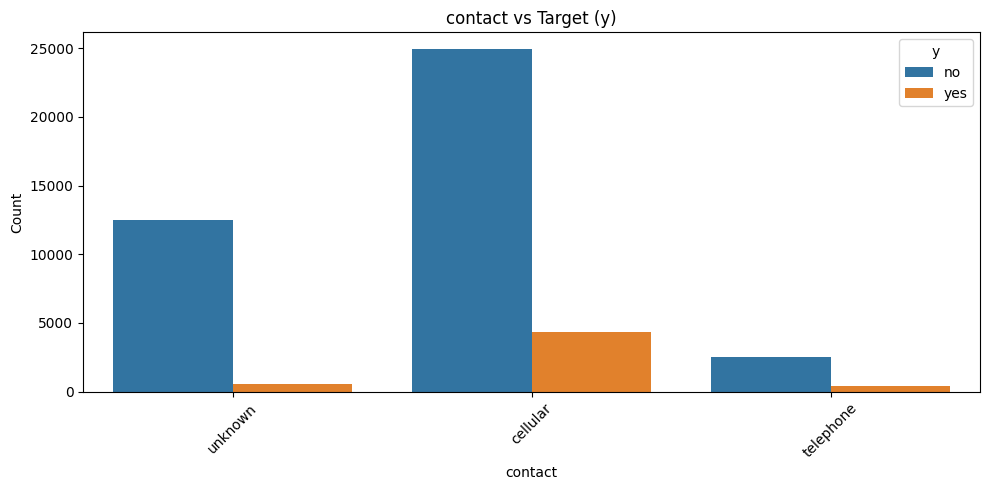

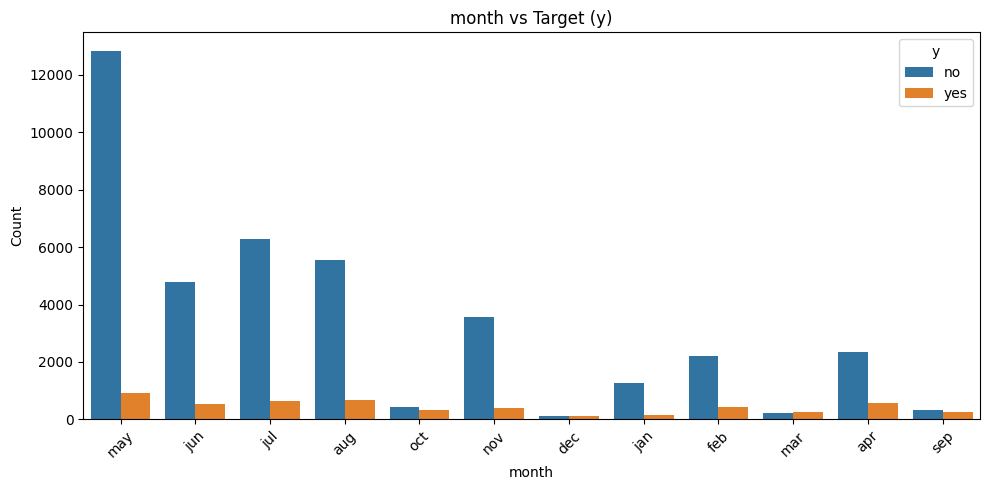

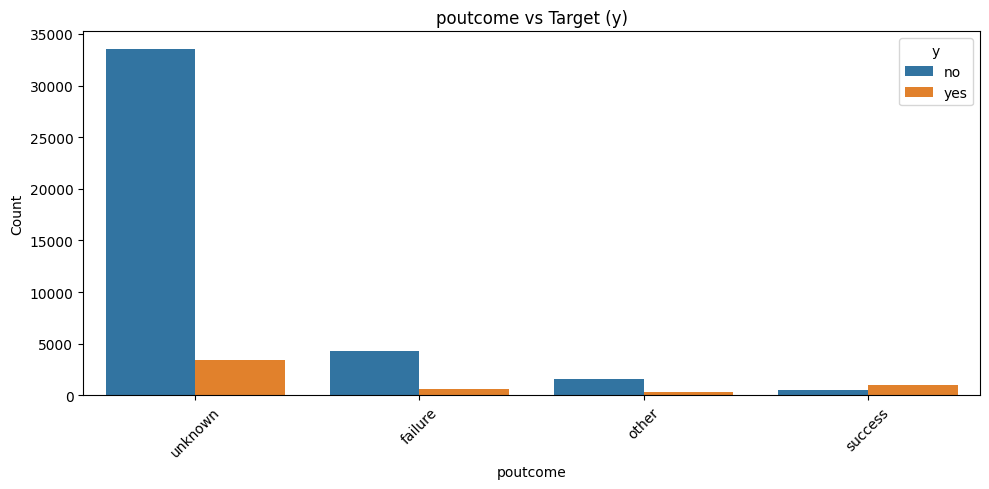

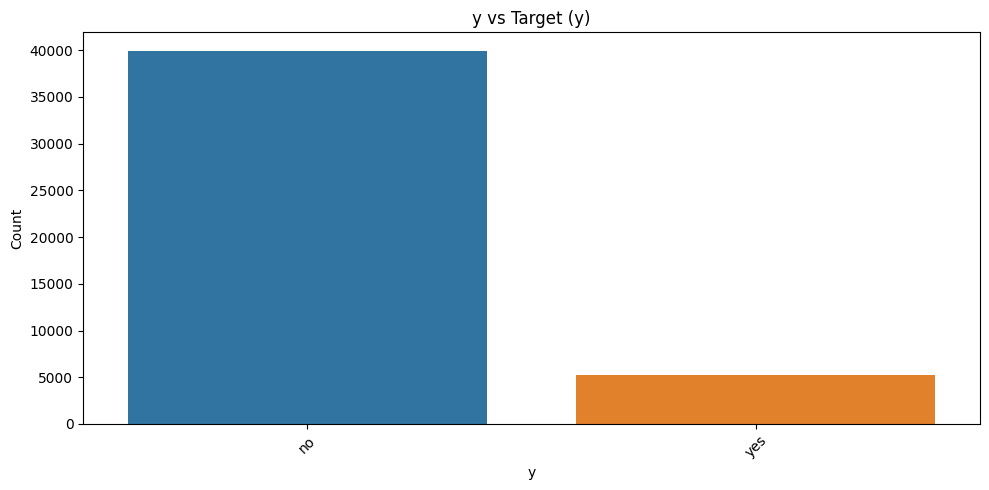

In [ ]:
for col in categorical_cols:
    plt.figure(figsize=(10, 5))

    sns.countplot(data=df, x=col, hue='y')

    plt.title(f'{col} vs Target (y)')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [ ]:
for col in categorical_cols:
    print(f"\n--- {col} vs y (%) ---")
    print(
        pd.crosstab(
            df[col],
            df['y'],
            normalize='index'
        ).mul(100).round(2)
    )


--- job vs y (%) ---
y                 no    yes
job                        
admin.         87.80  12.20
blue-collar    92.73   7.27
entrepreneur   91.73   8.27
housemaid      91.21   8.79
management     86.24  13.76
retired        77.21  22.79
self-employed  88.16  11.84
services       91.12   8.88
student        71.32  28.68
technician     88.94  11.06
unemployed     84.50  15.50
unknown        88.19  11.81

--- marital vs y (%) ---
y            no    yes
marital               
divorced  88.05  11.95
married   89.88  10.12
single    85.05  14.95

--- education vs y (%) ---
y             no    yes
education              
primary    91.37   8.63
secondary  89.44  10.56
tertiary   84.99  15.01
unknown    86.43  13.57

--- default vs y (%) ---
y           no    yes
default              
no       88.20  11.80
yes      93.62   6.38

--- housing vs y (%) ---
y          no   yes
housing            
no       83.3  16.7
yes      92.3   7.7

--- loan vs y (%) ---
y        no    yes
loan       

In [ ]:
for col in df.select_dtypes(include='object').columns:
   print(f"{col}: {(df[col] == 'unknown').sum()}")

job: 288
marital: 0
education: 1857
default: 0
housing: 0
loan: 0
contact: 13020
month: 0
poutcome: 36959
y: 0


In [ ]:
print((df['pdays']== -1).sum())

36954


## 3. Data Preprocessing and Train-Test Split

In this section, we prepare the dataset for machine learning by handling categorical and numerical features, encoding categorical variables, and splitting the data into training and testing sets. We also build a preprocessing pipeline to ensure consistent data transformation.

In [ ]:
df.drop(columns=['duration'], inplace=True)

In [ ]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous',
       'poutcome', 'y'],
      dtype='object')

In [ ]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.drop('y', errors='ignore')

categorical_cols = df.select_dtypes(include=['object']).columns

print("Numerical Columns:", list(numerical_cols))
print("Categorical Columns:", list(categorical_cols))

Numerical Columns: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical Columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']


In [ ]:
X = df.drop(columns=['y'])
y = df['y']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(36168, 15)
(9043, 15)
(36168,)
(9043,)


In [ ]:
numerical_cols = X.select_dtypes(include=['number']).columns

print(X[numerical_cols].skew().sort_values(ascending=False))

previous    41.846454
balance      8.360308
campaign     4.898650
pdays        2.615715
age          0.684818
day          0.093079
dtype: float64


In [ ]:
for col in numerical_cols:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((X[col] < lower) | (X[col] > upper)).sum()

    print(f"{col}: lower={lower:.2f}, upper={upper:.2f}, outliers={count}")

age: lower=10.50, upper=70.50, outliers=487
balance: lower=-1962.00, upper=3462.00, outliers=4729
day: lower=-11.50, upper=40.50, outliers=0
campaign: lower=-2.00, upper=6.00, outliers=3064
pdays: lower=-1.00, upper=-1.00, outliers=8257
previous: lower=0.00, upper=0.00, outliers=8257


In [ ]:
for col in ['age', 'balance', 'campaign', 'pdays', 'previous']:
    print(f"\n{col}")
    print(X[col].describe())


age
count    45211.000000
mean        40.936210
std         10.618762
min         18.000000
25%         33.000000
50%         39.000000
75%         48.000000
max         95.000000
Name: age, dtype: float64

balance
count     45211.000000
mean       1362.272058
std        3044.765829
min       -8019.000000
25%          72.000000
50%         448.000000
75%        1428.000000
max      102127.000000
Name: balance, dtype: float64

campaign
count    45211.000000
mean         2.763841
std          3.098021
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         63.000000
Name: campaign, dtype: float64

pdays
count    45211.000000
mean        40.197828
std        100.128746
min         -1.000000
25%         -1.000000
50%         -1.000000
75%         -1.000000
max        871.000000
Name: pdays, dtype: float64

previous
count    45211.000000
mean         0.580323
std          2.303441
min          0.000000
25%          0.000000
50%          0.000000


In [ ]:
categorical_cols = X.select_dtypes(include=['object']).columns

print(categorical_cols.tolist())

['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer

In [ ]:
ordinal_cols = ['education']

education_categories = [
    'primary',
    'secondary',
    'tertiary'
]

In [ ]:
onehot_cols = (
    categorical_cols
    .drop(ordinal_cols)
    .tolist()
)

In [ ]:

numerical_transformers = Pipeline(
    steps=[
        ('scaler', StandardScaler())
    ]
)

In [ ]:
onehot_transformers = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [ ]:
ordinal_transformers = Pipeline([
    ('encoder', OrdinalEncoder(
        categories=[education_categories],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('numerical', numerical_transformers, numerical_cols),
        ('ordinal', ordinal_transformers, ordinal_cols),
        ('nominal', onehot_transformers, onehot_cols)
    ],
    remainder='passthrough'
)
preprocessor

ColumnTransformer(remainder='passthrough',
                  transformers=[('numerical',
                                 Pipeline(steps=[('scaler', StandardScaler())]),
                                 Index(['age', 'balance', 'day', 'campaign', 'pdays', 'previous'], dtype='object')),
                                ('ordinal',
                                 Pipeline(steps=[('encoder',
                                                  OrdinalEncoder(categories=[['primary',
                                                                              'secondary',
                                                                              'tertiary']],
                                                                 handle_unknown='use_encoded_value',
                                                                 unknown_value=-1))]),
                                 ['education']),
                                ('nominal',
                                 Pipeline(steps=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['job', 'marital', 'default', 'housing',
                                  'loan', 'contact', 'month', 'poutcome'])])

In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(y_train)
y_test = label_encoder.transform(y_test)

## 4. Logistic Regression — Model Training and Evaluation

In this section, we train a Logistic Regression model using the preprocessed training data and evaluate its performance on the test data. We use accuracy, precision, recall, F1-score, classification report, and confusion matrix to assess the model's classification performance.

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:

lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        C=1.0,
        class_weight='balanced',
        max_iter=1000,
        random_state=42,
        solver='lbfgs',
        penalty='l2'
    ))
])
lr_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('numerical',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  Index(['age', 'balance', 'day', 'campaign', 'pdays', 'previous'], dtype='object')),
                                                 ('ordinal',
                                                  Pipeline(steps=[('encoder',
                                                                   OrdinalEncoder(categories=[['primary',
                                                                                               'secondary',
                                                                                               'tertiary']],
                                                                                  handle_unknown='use_encoded_value',
                                                                                  unknown_value=-1))]),
                                                  ['education']),
                                                 ('nominal',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['job', 'marital', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'poutcome'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [ ]:
lr_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('numerical',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  Index(['age', 'balance', 'day', 'campaign', 'pdays', 'previous'], dtype='object')),
                                                 ('ordinal',
                                                  Pipeline(steps=[('encoder',
                                                                   OrdinalEncoder(categories=[['primary',
                                                                                               'secondary',
                                                                                               'tertiary']],
                                                                                  handle_unknown='use_encoded_value',
                                                                                  unknown_value=-1))]),
                                                  ['education']),
                                                 ('nominal',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['job', 'marital', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'poutcome'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [ ]:
y_pred = lr_model.predict(X_test)

In [ ]:
print("Coefficients:", lr_model['model'].coef_)
print("Intercept:", lr_model['model'].intercept_)
print("Classes:", lr_model['model'].classes_)


print("Prediction Probabilities:\n", y_pred)

Coefficients: [[-0.01884895  0.08919586  0.00496776 -0.22098783 -0.00437936  0.06004284
   0.09285263  0.03432258 -0.07864853 -0.08583252 -0.35686752 -0.00741738
   0.48845898 -0.11128954 -0.09731119  0.35742021 -0.03898369  0.0857375
  -0.12352986  0.0804161  -0.18936638  0.17500932  0.11589544 -0.04983639
   0.27020334 -0.20414429  0.20966648 -0.14360743  0.48503713  0.2950464
  -0.71402448  0.05319935 -0.7435482   0.83103124 -0.28872254 -1.05025407
  -0.59611862  0.13165231  1.21536559 -0.4258318  -0.79003754  0.93837426
   0.79094908 -0.66422786 -0.41508208  1.68220714 -0.53683815]]
Intercept: [0.0677868]
Classes: [0 1]
Prediction Probabilities:
 [0 0 0 ... 0 1 0]


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Accuracy: 0.7552803273250027

Classification Report:

              precision    recall  f1-score   support

           0       0.94      0.77      0.85      7985
           1       0.27      0.63      0.38      1058

    accuracy                           0.76      9043
   macro avg       0.60      0.70      0.61      9043
weighted avg       0.86      0.76      0.79      9043



In [ ]:
print("Confusion Matrix:\n")
print(confusion_matrix(y_test, y_pred))

Confusion Matrix:

[[6164 1821]
 [ 392  666]]


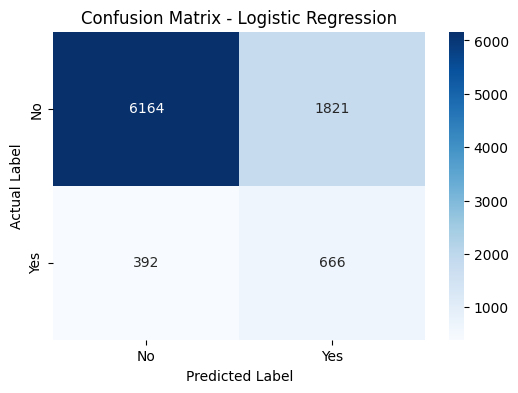

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

## 5. Decision Tree — Model Training, Hyperparameter Tuning and Evaluation

In this section, we train a Decision Tree classifier and optimize its hyperparameters using GridSearchCV. We evaluate the model's performance on the test data using classification metrics and a confusion matrix.

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

In [63]:
d_tree_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(random_state=42))
])

In [64]:
grid = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [3, 5, 7, 10, None],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 5, 10],
    "model__max_features": [None, "sqrt", "log2"],
    "model__class_weight": [None, "balanced"]
}

In [65]:
grid_search = GridSearchCV(
    estimator=d_tree_model,
    param_grid=grid,
    cv=3,
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('numerical',
                                                                         Pipeline(steps=[('scaler',
                                                                                          StandardScaler())]),
                                                                         Index(['age', 'balance', 'day', 'campaign', 'pdays', 'previous'], dtype='object')),
                                                                        ('ordinal',
                                                                         Pipeline(steps=[('encoder',
                                                                                          OrdinalEncoder(categories=[['primary',
                                                                                                                      'secondary',
                                                                                                                      'tertiary'...
                                                                          'default',
                                                                          'housing',
                                                                          'loan',
                                                                          'contact',
                                                                          'month',
                                                                          'poutcome'])])),
                                       ('model',
                                        DecisionTreeClassifier(random_state=42))]),
             param_grid={'model__class_weight': [None, 'balanced'],
                         'model__criterion': ['gini', 'entropy'],
                         'model__max_depth': [3, 5, 7, 10, None],
                         'model__max_features': [None, 'sqrt', 'log2'],
                         'model__min_samples_leaf': [1, 2, 5, 10],
                         'model__min_samples_split': [2, 5, 10, 20]})

In [66]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV Score:", grid_search.best_score_)

Best Parameters: {'model__class_weight': None, 'model__criterion': 'gini', 'model__max_depth': 7, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5, 'model__min_samples_split': 20}
Best CV Score: 0.8930269851802698


In [67]:
y_pred_dt = grid_search.predict(X_test)

In [68]:
print("Test Accuracy:", accuracy_score(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, digits=2))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Test Accuracy: 0.891850049762247

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.99      0.94      7985
           1       0.63      0.19      0.29      1058

    accuracy                           0.89      9043
   macro avg       0.76      0.59      0.61      9043
weighted avg       0.87      0.89      0.87      9043


Confusion Matrix:
[[7867  118]
 [ 860  198]]


## 6. Random Forest — Model Training, Hyperparameter Tuning and Evaluation

In this section, we train a Random Forest classifier and optimize its hyperparameters using GridSearchCV. We evaluate the model's performance on the test data using classification metrics and a confusion matrix.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
ran_f_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(random_state=42))
])

In [ ]:
grid = {
    'model__n_estimators': [100, 200],
    'model__criterion': ['gini', 'entropy'],
    'model__max_depth': [10, 15, None],
    'model__min_samples_split': [2, 10],
    'model__min_samples_leaf': [1, 2],
    'model__max_features': ['sqrt', 'log2']
}



In [ ]:
grid_search = GridSearchCV(
    estimator=ran_f_model,
    param_grid=grid,
    cv=5,

)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best Parameters: {'model__criterion': 'entropy', 'model__max_depth': None, 'model__max_features': 'log2', 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best CV Accuracy: 0.894934694954212


In [51]:
y_pred_dt = grid_search.predict(X_test)
print("Test Accuracy:", accuracy_score(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, digits=2))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Test Accuracy: 0.8964945261528254

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.99      0.94      7985
           1       0.70      0.20      0.31      1058

    accuracy                           0.90      9043
   macro avg       0.80      0.60      0.63      9043
weighted avg       0.88      0.90      0.87      9043


Confusion Matrix:
[[7892   93]
 [ 843  215]]


## 7. Support Vector Machine (SVM) — Model Training, Hyperparameter Tuning and Evaluation

In this section, we train a Support Vector Machine classifier and optimize its hyperparameters using GridSearchCV. We evaluate the model's performance on the test data using classification metrics and a confusion matrix.

In [ ]:

from sklearn.svm import LinearSVC



svm_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearSVC(
        max_iter=10000,
        random_state=42
    ))
])


grid_svm = {
    'model__C': [0.01, 0.1, 1, 10],
    'model__class_weight': [None, 'balanced']
}


grid_search_svm = GridSearchCV(
    estimator=svm_model,
    param_grid=grid_svm,
    cv=5

)


grid_search_svm.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search_svm.best_params_)

print("\nBest CV F1 Score:")
print(grid_search_svm.best_score_)


y_pred_svm = grid_search_svm.predict(X_test)


print("\nTest Accuracy:")
print(accuracy_score(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    digits=2
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

Best Parameters:
{'model__C': 0.01, 'model__class_weight': None}

Best CV F1 Score:
0.8926675845712374

Test Accuracy:
0.893177043016698

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.99      0.94      7985
           1       0.66      0.18      0.28      1058

    accuracy                           0.89      9043
   macro avg       0.78      0.58      0.61      9043
weighted avg       0.87      0.89      0.87      9043


Confusion Matrix:
[[7886   99]
 [ 867  191]]


## 7. K-Nearest Neighbors (KNN) — Model Training, Hyperparameter Tuning and Evaluation

In this section, we train a K-Nearest Neighbors classifier and optimize its hyperparameters using GridSearchCV. We evaluate the model's performance on the test data using classification metrics and a confusion matrix.

In [ ]:

from sklearn.neighbors import KNeighborsClassifier

knn_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier())
])


grid_knn = {
    'model__n_neighbors': [5, 11, 21],
    'model__weights': ['uniform', 'distance'],
    'model__metric': ['euclidean', 'manhattan']
}


grid_search_knn = GridSearchCV(
    estimator=knn_model,
    param_grid=grid_knn,
    cv=5
)


grid_search_knn.fit(X_train, y_train)


print("Best Parameters:")
print(grid_search_knn.best_params_)

print("\nBest CV F1 Score:")
print(grid_search_knn.best_score_)


y_pred_knn = grid_search_knn.predict(X_test)


print("\nTest Accuracy:")
print(accuracy_score(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_knn,
    digits=2
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

Best Parameters:
{'model__metric': 'manhattan', 'model__n_neighbors': 21, 'model__weights': 'uniform'}

Best CV F1 Score:
0.8920039939207456

Test Accuracy:
0.8948357845847617

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.99      0.94      7985
           1       0.71      0.17      0.27      1058

    accuracy                           0.89      9043
   macro avg       0.81      0.58      0.61      9043
weighted avg       0.88      0.89      0.86      9043


Confusion Matrix:
[[7914   71]
 [ 880  178]]


In [ ]:
print("Scoring:", grid_search_knn.scoring)
print("Best CV Score:", grid_search_knn.best_score_)
print("Best Parameters:", grid_search_knn.best_params_)

Scoring: None
Best CV Score: 0.8920039939207456
Best Parameters: {'model__metric': 'manhattan', 'model__n_neighbors': 21, 'model__weights': 'uniform'}


## 9. Feature Relationship Analysis

In this section, we examine the correlation between numerical features and analyze subscription rates across categorical features to identify patterns associated with the target variable.

In [ ]:
for name, y in [('y_train', y_train), ('y_test', y_test)]:
    counts = pd.Series(y).value_counts()
    percentages = pd.Series(y).value_counts(normalize=True) * 100

    print(f"\n{name}")
    print("No (0):", counts.get(0, 0), f"({percentages.get(0, 0):.2f}%)")
    print("Yes (1):", counts.get(1, 0), f"({percentages.get(1, 0):.2f}%)")
    print("Total:", counts.sum())


y_train
No (0): 31937 (88.30%)
Yes (1): 4231 (11.70%)
Total: 36168

y_test
No (0): 7985 (88.30%)
Yes (1): 1058 (11.70%)
Total: 9043


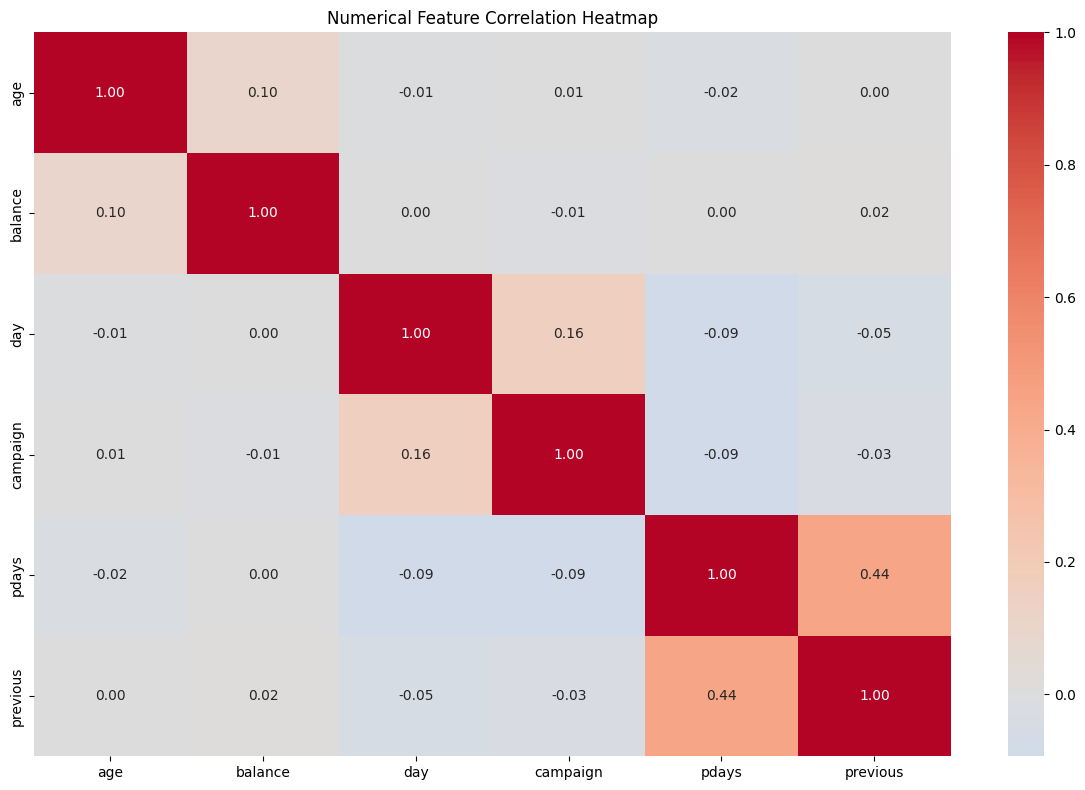

In [ ]:
corr_matrix = X_train[numerical_cols].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Numerical Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

campaign   -0.071978
day        -0.026595
age         0.024704
balance     0.055025
previous    0.088847
pdays       0.100703
Name: y, dtype: float64


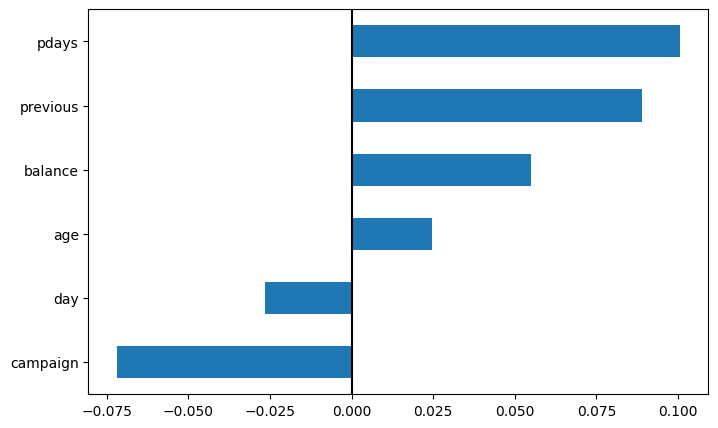

In [ ]:
data = X_train[numerical_cols].copy()
data['y'] = y_train

corr = data.corr()['y'].drop('y')

print(corr.sort_values())

corr.sort_values().plot(kind='barh', figsize=(8, 5))
plt.axvline(0, color='black')
plt.show()

In [ ]:
data = X_train[categorical_cols].copy()
data['y'] = y_train

for col in categorical_cols:
    print('\n', col)
    print('Count:')
    print(data[col].value_counts())

    print('Yes Rate (%):')
    print((data.groupby(col)['y'].mean() * 100).round(2))


 job
Count:
job
blue-collar      7830
management       7511
technician       6068
admin.           4141
services         3348
retired          1812
self-employed    1243
entrepreneur     1186
unemployed       1024
housemaid        1013
student           758
unknown           234
Name: count, dtype: int64
Yes Rate (%):
job
admin.           12.29
blue-collar       7.29
entrepreneur      8.52
housemaid         8.39
management       13.86
retired          22.96
self-employed    11.42
services          8.90
student          28.89
technician       10.93
unemployed       15.43
unknown          11.97
Name: y, dtype: float64

 marital
Count:
marital
married     21771
single      10227
divorced     4170
Name: count, dtype: int64
Yes Rate (%):
marital
divorced    12.25
married     10.04
single      15.01
Name: y, dtype: float64

 education
Count:
education
secondary    18561
tertiary     10594
primary       5531
unknown       1482
Name: count, dtype: int64
Yes Rate (%):
education
primary       8

## 10. Error Analysis

In this section, we analyze misclassified observations from the Logistic Regression and Random Forest models to understand their prediction errors and identify potential weaknesses.

In [53]:
error_data = X_test.copy()
error_data['actual'] = y_test
error_data['lr_pred'] = lr_model.predict(X_test)
error_data['rf_pred'] = grid_search.predict(X_test)

yes_data = error_data[error_data['actual'] == 1]

result = yes_data.groupby('poutcome').agg(
    total_yes=('actual', 'count'),
    lr_missed=('lr_pred', lambda x: (x == 0).sum()),
    rf_missed=('rf_pred', lambda x: (x == 0).sum())
)

result['lr_miss_%'] = (
    result['lr_missed'] / result['total_yes'] * 100
).round(2)

result['rf_miss_%'] = (
    result['rf_missed'] / result['total_yes'] * 100
).round(2)

print(result)

          total_yes  lr_missed  rf_missed  lr_miss_%  rf_miss_%
poutcome                                                       
failure         140         60        139      42.86      99.29
other            62         17         58      27.42      93.55
success         199          0         25       0.00      12.56
unknown         657        315        621      47.95      94.52


## 11. Threshold Tuning for Logistic Regression and Random Forest

In this section, we experiment with different classification thresholds for Logistic Regression and Random Forest to examine their effects on precision, recall, F1-score, and other evaluation metrics.

In [57]:
from sklearn.base import clone
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

lr_val_model = clone(lr_model)
rf_val_model = clone(grid_search.best_estimator_)

lr_val_model.fit(X_fit, y_fit)
rf_val_model.fit(X_fit, y_fit)

lr_prob = lr_val_model.predict_proba(X_val)[:, 1]
rf_prob = rf_val_model.predict_proba(X_val)[:, 1]

results = []

for name, prob in [('Logistic Regression', lr_prob), ('Random Forest', rf_prob)]:
    for threshold in [0.2, 0.3, 0.4, 0.5]:
        pred = (prob >= threshold).astype(int)

        results.append({
            'Model': name,
            'Threshold': threshold,
            'Accuracy': accuracy_score(y_val, pred),
            'Precision': precision_score(y_val, pred, zero_division=0),
            'Recall': recall_score(y_val, pred, zero_division=0),
            'F1-score': f1_score(y_val, pred, zero_division=0)
        })

results = pd.DataFrame(results)
print(results.round(3).to_string(index=False))

              Model  Threshold  Accuracy  Precision  Recall  F1-score
Logistic Regression        0.2     0.249      0.131   0.966     0.231
Logistic Regression        0.3     0.383      0.148   0.900     0.254
Logistic Regression        0.4     0.573      0.188   0.798     0.304
Logistic Regression        0.5     0.755      0.266   0.622     0.373
      Random Forest        0.2     0.858      0.421   0.573     0.485
      Random Forest        0.3     0.885      0.510   0.455     0.481
      Random Forest        0.4     0.897      0.614   0.318     0.419
      Random Forest        0.5     0.897      0.701   0.202     0.314


## 12. Random Forest Evaluation at Different Thresholds

In this section, we evaluate the Random Forest model at classification thresholds of 0.5 and 0.2 using classification metrics and confusion matrices to understand how threshold adjustments affect its predictions.

In [58]:
rf_prob_test = grid_search.predict_proba(X_test)[:, 1]

for threshold in [0.5, 0.2]:
    y_pred = (rf_prob_test >= threshold).astype(int)

    print("\nThreshold:", threshold)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred, digits=2))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))


Threshold: 0.5
Accuracy: 0.8964945261528254
              precision    recall  f1-score   support

           0       0.90      0.99      0.94      7985
           1       0.70      0.20      0.31      1058

    accuracy                           0.90      9043
   macro avg       0.80      0.60      0.63      9043
weighted avg       0.88      0.90      0.87      9043

Confusion Matrix:
[[7892   93]
 [ 843  215]]

Threshold: 0.2
Accuracy: 0.8583434700873603
              precision    recall  f1-score   support

           0       0.94      0.90      0.92      7985
           1       0.42      0.56      0.48      1058

    accuracy                           0.86      9043
   macro avg       0.68      0.73      0.70      9043
weighted avg       0.88      0.86      0.87      9043

Confusion Matrix:
[[7165  820]
 [ 461  597]]


## 13. Final Model Performance Comparison

In this section, we compare the baseline performance of all trained models with the results obtained after threshold tuning for Logistic Regression and Random Forest. This comparison helps assess the impact of threshold adjustments on model performance.

In [60]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'SVM',
        'KNN',
        'Logistic Regression',
        'Logistic Regression',
        'Random Forest',
        'Random Forest'
    ],
    'Threshold': [
        0.5, 0.5, 0.5, 0.5, 0.5,
        0.4, 0.5, 0.2, 0.5
    ],
    'Evaluation': [
        'Test', 'Test', 'Test', 'Test', 'Test',
        'Validation', 'Validation',
        'Validation', 'Validation'
    ],
    'Accuracy': [
        0.7553, 0.8919, 0.8965, 0.8932, 0.8948,
        0.573, 0.755, 0.858, 0.897
    ],
    'Yes Precision': [
        0.27, 0.63, 0.70, 0.66, 0.71,
        0.188, 0.266, 0.421, 0.701
    ],
    'Yes Recall': [
        0.63, 0.19, 0.20, 0.18, 0.17,
        0.798, 0.622, 0.573, 0.202
    ],
    'Yes F1-score': [
        0.38, 0.29, 0.31, 0.28, 0.27,
        0.304, 0.373, 0.485, 0.314
    ]
})

print(results.to_string(index=False))

              Model  Threshold Evaluation  Accuracy  Yes Precision  Yes Recall  Yes F1-score
Logistic Regression        0.5       Test    0.7553          0.270       0.630         0.380
      Decision Tree        0.5       Test    0.8919          0.630       0.190         0.290
      Random Forest        0.5       Test    0.8965          0.700       0.200         0.310
                SVM        0.5       Test    0.8932          0.660       0.180         0.280
                KNN        0.5       Test    0.8948          0.710       0.170         0.270
Logistic Regression        0.4 Validation    0.5730          0.188       0.798         0.304
Logistic Regression        0.5 Validation    0.7550          0.266       0.622         0.373
      Random Forest        0.2 Validation    0.8580          0.421       0.573         0.485
      Random Forest        0.5 Validation    0.8970          0.701       0.202         0.314


## 14. Final Model Selection

In this section, we summarize the evaluation results and explain the reasons for selecting the Decision Tree classifier as the final model for the Bank Marketing classification task.

In [61]:
print("Baseline Test Results")

print(
    results[results['Evaluation'] == 'Test']
    .to_string(index=False)
)

print("\nThreshold Validation Results")

print(
    results[results['Evaluation'] == 'Validation']
    .to_string(index=False)
)

Baseline Test Results
              Model  Threshold Evaluation  Accuracy  Yes Precision  Yes Recall  Yes F1-score
Logistic Regression        0.5       Test    0.7553           0.27        0.63          0.38
      Decision Tree        0.5       Test    0.8919           0.63        0.19          0.29
      Random Forest        0.5       Test    0.8965           0.70        0.20          0.31
                SVM        0.5       Test    0.8932           0.66        0.18          0.28
                KNN        0.5       Test    0.8948           0.71        0.17          0.27

Threshold Validation Results
              Model  Threshold Evaluation  Accuracy  Yes Precision  Yes Recall  Yes F1-score
Logistic Regression        0.4 Validation     0.573          0.188       0.798         0.304
Logistic Regression        0.5 Validation     0.755          0.266       0.622         0.373
      Random Forest        0.2 Validation     0.858          0.421       0.573         0.485
      Random Fores

## 15. Conclusion

In this project, we explored the Bank Marketing dataset, performed exploratory data analysis, and applied several machine learning classification algorithms. We evaluated the models using classification metrics and confusion matrices, conducted error analysis, and investigated threshold tuning for selected models. Finally, we selected the Decision Tree classifier based on our evaluation results. This project provided insights into customer subscription patterns and the application of machine learning techniques to bank marketing prediction.